# TRUSTSR Lab 03.06 — Correlated Outages and Ambiguous Timeouts

**Phase:** Lab 03 — Reliability and evidence integrity  
**Status:** Synthetic simulation | Version 0.1.0

## Motivation
Lab 03.05 modeled independent pre-storage failures only. Real delivery failures may be correlated over time, and a timeout can happen after the receiver has already stored an event. This lab adds two explicitly simulated behaviors:
1. **Correlated outage windows:** while an outage is active, attempts fail before reaching the receiver.
2. **Ambiguous timeout-after-store:** the receiver persists an event, but the sender receives a timeout and retries the same stable event ID.

## Model
- A fixed number of events is sent in order.
- Each condition uses an injected outage schedule and injected post-store timeout probability.
- Receiver uniqueness is enforced by `event_id`.
- A duplicate with the same payload is ignored; the same ID with a different payload is a conflict.
- Metrics include delivered logical events, missing events, receiver records, duplicate attempts, attempts per event, and false sender uncertainty.
- A deterministic seed makes this synthetic run repeatable.

**Evidence boundary:** this is a local simulation, not a real network, remote receiver, or production fault-injection experiment.

## 1. Imports and experiment configuration

In [1]:
import random, json, sqlite3, tempfile, os, hashlib, sys
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261011
N_EVENTS = 500
OUTAGE_WINDOW_STARTS = [0, 100, 300]
OUTAGE_WINDOW_LENGTH = 20
POST_STORE_TIMEOUT_PROBABILITIES = [0.0, 0.1, 0.3]
RETRY_LIMITS = [1, 2, 3, 5]
print("Python:", sys.version.split()[0])
print("SQLite:", sqlite3.sqlite_version)
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence classification: synthetic simulation; no network calls")
print({"seed":SEED,"events":N_EVENTS,"outage_starts":OUTAGE_WINDOW_STARTS,
       "outage_window_length":OUTAGE_WINDOW_LENGTH,
       "post_store_timeout_probabilities":POST_STORE_TIMEOUT_PROBABILITIES,
       "retry_limits":RETRY_LIMITS})

Python: 3.12.3
SQLite: 3.45.1
Execution UTC: 2026-10-11T10:26:36.175949+00:00
Evidence classification: synthetic simulation; no network calls
{'seed': 20261011, 'events': 500, 'outage_starts': [0, 100, 300], 'outage_window_length': 20, 'post_store_timeout_probabilities': [0.0, 0.1, 0.3], 'retry_limits': [1, 2, 3, 5]}


## 2. Simulation engine

In [2]:
def run_scenario(n_events, retry_limit, timeout_p, seed):
    rng = random.Random(seed)
    fd, path = tempfile.mkstemp(prefix="trustsr_lab03_06_", suffix=".sqlite")
    os.close(fd)
    db = sqlite3.connect(path)
    db.execute("CREATE TABLE received (event_id TEXT PRIMARY KEY, payload_hash TEXT NOT NULL)")
    attempts_total = duplicate_attempts = timeout_after_store = 0
    event_rows = []
    outage_windows = [(s, s + OUTAGE_WINDOW_LENGTH) for s in OUTAGE_WINDOW_STARTS]

    for i in range(n_events):
        event_id = f"event-{i:05d}"
        payload = {"sequence": i, "kind": "synthetic_checkpoint_event"}
        payload_hash = hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()
        delivered = False
        attempts = 0
        sender_saw_ack = False

        for attempt in range(1, retry_limit + 1):
            attempts += 1
            attempts_total += 1
            in_outage = any(start <= i < end for start, end in outage_windows)
            if in_outage:
                continue  # correlated outage: every attempt fails before receiver storage

            existing = db.execute("SELECT payload_hash FROM received WHERE event_id=?", (event_id,)).fetchone()
            if existing:
                if existing[0] != payload_hash:
                    raise RuntimeError("Unexpected idempotency-key payload conflict")
                duplicate_attempts += 1
                delivered = True
                sender_saw_ack = True
                break

            db.execute("INSERT INTO received VALUES (?,?)", (event_id, payload_hash))
            delivered = True
            if rng.random() < timeout_p:
                # Receiver stored the event, but sender did not observe the acknowledgement.
                timeout_after_store += 1
                continue
            sender_saw_ack = True
            break

        event_rows.append({
            "event_id":event_id, "retry_limit":retry_limit, "timeout_probability":timeout_p,
            "attempts":attempts, "receiver_stored":db.execute("SELECT 1 FROM received WHERE event_id=?",(event_id,)).fetchone() is not None,
            "sender_observed_ack":sender_saw_ack, "delivered":delivered,
            "in_correlated_outage":any(s <= i < e for s,e in outage_windows)
        })

    receiver_count = int(db.execute("SELECT COUNT(*) FROM received").fetchone()[0])
    db.close()
    os.remove(path)
    df = pd.DataFrame(event_rows)
    intended = len(df)
    summary = {
        "retry_limit":retry_limit, "post_store_timeout_probability":timeout_p,
        "intended_events":intended, "receiver_records":receiver_count,
        "missing_at_receiver":intended-receiver_count,
        "receiver_coverage_rate":receiver_count/intended,
        "duplicate_attempts":duplicate_attempts, "timeout_after_store_events":timeout_after_store,
        "mean_attempts_per_event":attempts_total/intended,
        "stored_but_sender_ack_missing":int((df["receiver_stored"] & ~df["sender_observed_ack"]).sum())
    }
    return summary, event_rows

print("Simulation engine defined.")

Simulation engine defined.


## 3. Run scenarios

In [3]:
summary_rows, event_rows = [], []
scenario_index = 0
for timeout_p in POST_STORE_TIMEOUT_PROBABILITIES:
    for retry_limit in RETRY_LIMITS:
        scenario_index += 1
        summary, rows = run_scenario(N_EVENTS, retry_limit, timeout_p, SEED + scenario_index)
        summary_rows.append(summary)
        event_rows.extend(rows)

summary_df = pd.DataFrame(summary_rows)
event_df = pd.DataFrame(event_rows)
display(summary_df)
print("Scenarios:", len(summary_df), "| Event records:", len(event_df))
assert len(summary_df) == len(POST_STORE_TIMEOUT_PROBABILITIES) * len(RETRY_LIMITS)
assert len(event_df) == N_EVENTS * len(summary_df)
assert summary_df["receiver_coverage_rate"].between(0,1).all()
assert (summary_df["receiver_records"] + summary_df["missing_at_receiver"] == N_EVENTS).all()
print("Scenario structure assertions passed.")

    retry_limit  post_store_timeout_probability  intended_events  receiver_records  missing_at_receiver  receiver_coverage_rate  duplicate_attempts  timeout_after_store_events  \
0             1                             0.0              500               440                   60                    0.88                   0                           0   
1             2                             0.0              500               440                   60                    0.88                   0                           0   
2             3                             0.0              500               440                   60                    0.88                   0                           0   
3             5                             0.0              500               440                   60                    0.88                   0                           0   
4             1                             0.1              500               440                   60  

Scenarios: 12 | Event records: 6000
Scenario structure assertions passed.


## 4. Plot coverage, duplicate attempts, and workload

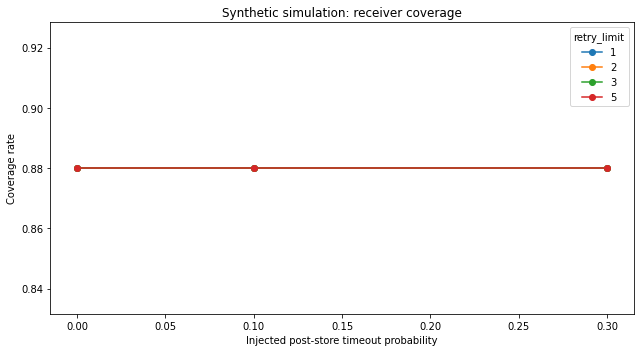

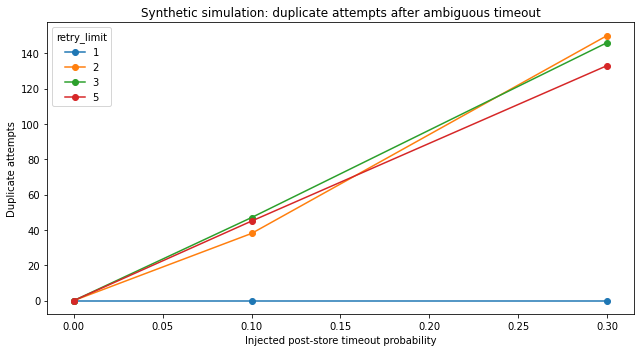

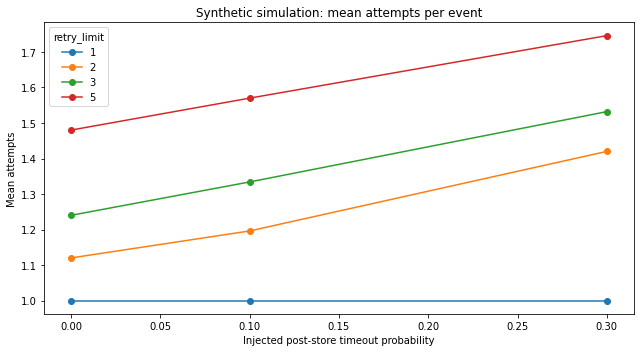

In [4]:
for metric, title, ylabel in [
    ("receiver_coverage_rate","Synthetic simulation: receiver coverage","Coverage rate"),
    ("duplicate_attempts","Synthetic simulation: duplicate attempts after ambiguous timeout","Duplicate attempts"),
    ("mean_attempts_per_event","Synthetic simulation: mean attempts per event","Mean attempts")
]:
    pivot = summary_df.pivot(index="post_store_timeout_probability", columns="retry_limit", values=metric)
    ax = pivot.plot(marker="o", figsize=(9,5))
    ax.set_title(title)
    ax.set_xlabel("Injected post-store timeout probability")
    ax.set_ylabel(ylabel)
    plt.tight_layout()
    plt.show()

## 5. Assertions for idempotency and correlated outage semantics

In [5]:
# Outage windows cover 60 unique event indices: 0-19, 100-119, 300-319.
outage_indices = set()
for start in OUTAGE_WINDOW_STARTS:
    outage_indices.update(range(start, min(start + OUTAGE_WINDOW_LENGTH, N_EVENTS)))
assert len(outage_indices) == 60

# Across each scenario, those outage events are not stored because every retry fails before receiver access.
for _, group in event_df.groupby(["retry_limit","timeout_probability"]):
    outage_rows = group[group["in_correlated_outage"]]
    assert len(outage_rows) == len(outage_indices)
    assert not outage_rows["receiver_stored"].any()

# Any stored-but-unacknowledged events must be a subset of injected timeout-after-store events.
for _, row in summary_df.iterrows():
    assert row["stored_but_sender_ack_missing"] >= 0
    assert row["receiver_records"] <= N_EVENTS

# With timeout probability 0 and no retries, duplicate attempts are zero.
zero_timeout_one_retry = summary_df[(summary_df["post_store_timeout_probability"]==0.0)&(summary_df["retry_limit"]==1)].iloc[0]
assert zero_timeout_one_retry["duplicate_attempts"] == 0
print("Idempotency and outage semantics assertions passed.")

Idempotency and outage semantics assertions passed.


## 6. Export CSV artifacts

In [6]:
summary_df.to_csv("trustsr_lab03_06_correlated_outage_summary.csv", index=False)
event_df.to_csv("trustsr_lab03_06_event_level_results.csv", index=False)
outage_df = event_df[event_df["in_correlated_outage"]].copy()
outage_df.to_csv("trustsr_lab03_06_outage_event_results.csv", index=False)
print("CSV exports created:")
print("- trustsr_lab03_06_correlated_outage_summary.csv")
print("- trustsr_lab03_06_event_level_results.csv")
print("- trustsr_lab03_06_outage_event_results.csv")
print("Classification: synthetic simulation only.")

CSV exports created:
- trustsr_lab03_06_correlated_outage_summary.csv
- trustsr_lab03_06_event_level_results.csv
- trustsr_lab03_06_outage_event_results.csv
Classification: synthetic simulation only.


## 7. Interpretation and limitations

### What the synthetic run can show
It can demonstrate the consequences of the injected outage windows and ambiguous timeout-after-store behavior in this specific model. A stable event ID plus a receiver uniqueness constraint can prevent duplicate stored rows when a retry follows a post-store timeout.

### Critical model limitation
The outage windows are keyed to event index and apply to every retry of that event. Therefore, retries do **not** recover events inside those windows. This intentionally models a persistent outage for those events; it is not a general model of real temporal outage dynamics.

### What is not demonstrated
- No real network, remote service, distributed database, or production system was tested.
- No latency, throughput, backoff, concurrent senders, rate limits, or host failures were measured.
- The timeout probability is assumed, not empirically estimated.
- Local SQLite uniqueness does not prove end-to-end exactly-once delivery across external systems.

### Defensible wording
“In this synthetic model, a unique event ID prevented duplicate receiver rows after injected ambiguous timeouts; events assigned to persistent outage windows remained missing despite retries.”
Do not describe this as production reliability evidence.